# 03 - Logistic Regression

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
from src.features import get_xy
from src.pipeline import build_model, predict_proba
from src.evaluation import evaluate_and_save, plot_curves, score_at, best_threshold
from sklearn.metrics import average_precision_score

df = pd.read_parquet(C.CLEAN_PATH)
X_train, y_train, _ = get_xy(df, "train")
X_val, y_val, _ = get_xy(df, "val")
X_test, y_test, _ = get_xy(df, "test")
print(X_train.shape, X_val.shape, X_test.shape)

(384548, 13) (81129, 13) (80445, 13)


## Tuning: try three values of C (regularization). Best one is chosen on the validation set.

In [2]:
grid = [{"C": c} for c in [0.01, 0.1, 1.0]]
results, models = [], []
for params in grid:
    t = time.time()
    m = build_model("logistic_regression", **params)
    m.fit(X_train, y_train)
    ap = average_precision_score(y_val, predict_proba(m, X_val))
    results.append({**params, "val_pr_auc": round(ap, 4), "seconds": round(time.time() - t, 1)})
    models.append(m)
tuning = pd.DataFrame(results)
display(tuning.sort_values("val_pr_auc", ascending=False))
i = int(tuning["val_pr_auc"].idxmax())
model, best_params = models[i], grid[i]
print("Best settings:", best_params)

,C,val_pr_auc,seconds
0,0.01,0.0951,2.2
1,0.10,0.0951,2.1
2,1.00,0.0951,2.1


Best settings: {'C': 0.01}


## Evaluate on validation and test

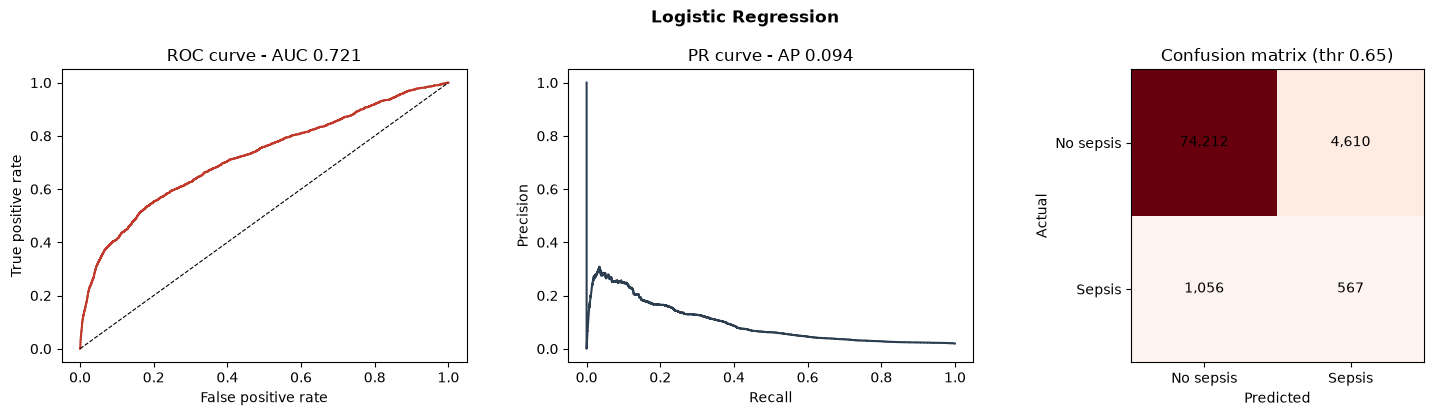

,val,test
roc_auc,0.690,0.721
pr_auc,0.095,0.094
precision,0.122,0.110
recall,0.341,0.349
specificity,0.946,0.942
f1,0.180,0.167
f2,0.251,0.243
balanced_accuracy,0.644,0.645


In [3]:
p_val = predict_proba(model, X_val)
p_test = predict_proba(model, X_test)
res = evaluate_and_save("logistic_regression", y_val, p_val, y_test, p_test, extra={"params": best_params, "tuning": tuning.to_dict("records")})
plot_curves(y_test, p_test, "Logistic Regression", res["test"]["threshold"])
pd.DataFrame(res).loc[["roc_auc","pr_auc","precision","recall","specificity","f1","f2","balanced_accuracy"], ["val","test"]].round(3)

## Which features matter? (scaled coefficients)

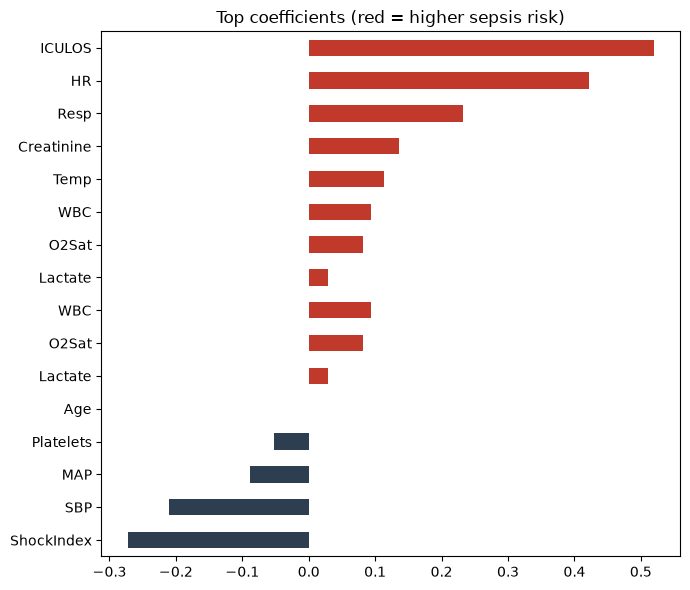

In [4]:
coef = pd.Series(model.named_steps["model"].coef_[0], index=X_train.columns).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
top.plot.barh(figsize=(7, 6), color=["#2c3e50" if v < 0 else "#c0392b" for v in top])
plt.title("Top coefficients (red = higher sepsis risk)"); plt.tight_layout()
plt.savefig(C.FIG_DIR / "logreg_coefficients.png", dpi=130); plt.show()